# JS09 - Lab 5
## Testing ANN Performance with Query Recall

Untuk membandingkan ANN secara adil, dipakai dua metrik:

* **Recall** - berapa banyak tetangga hasil pencarian yang benar-benar sama dengan hasil
  *exact nearest neighbor*. Nilai mendekati 1 berarti hasilnya hampir identik dengan pencarian exact.
* **QPS / query time** - kecepatan menjawab query. Semakin kecil waktu per query, semakin cepat.

Plot yang dihasilkan menyerupai **ANN-Benchmarks** (<https://github.com/erikbern/ann-benchmarks>):
sumbu X adalah recall, sumbu Y adalah waktu query. Posisi ideal adalah **kanan bawah**
(recall tinggi, waktu kecil).

Parameter yang diuji divariasikan pada tiap library:

| Library | Parameter | Nilai |
| --- | --- | --- |
| Annoy | `search_k` | 200, 500, 1000, 2000 |
| FAISS IVF | `nprobe` | 1, 5, 10, 20 |
| HNSW | `ef` | 50, 100, 200, 400 |

### Step 1 - Import Libraries and Build the Dataset

In [1]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Random dataset
# -------------------------------
d = 128        # dimension
nb = 100000    # number of database vectors
nq = 1000      # number of queries

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

print("Database:", xb.shape)
print("Queries :", xq.shape)

Database: (100000, 128)
Queries : (1000, 128)


### Step 2 - Ground Truth with FAISS Brute Force

Hasil pencarian exact untuk seluruh 1.000 query dihitung sekali, lalu dipakai sebagai acuan
recall oleh semua metode approximate.

In [2]:
# -------------------------------
# Ground truth with FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10

start = time.perf_counter()
_, gt_idx = index_flat.search(xq, k)
gt_time = (time.perf_counter() - start) * 1000 / nq

print("Ground truth shape:", gt_idx.shape)
print("Exact query time:", round(gt_time, 4), "ms/query")

Ground truth shape: (1000, 10)
Exact query time: 0.2081 ms/query


### Step 3 - Recall Function

In [3]:
# -------------------------------
# Recall function
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

### Step 4 - Annoy Benchmark

`search_k` menentukan berapa banyak node yang diperiksa saat menelusuri tree. Nilai besar berarti
recall naik tetapi query melambat. Index dibangun **sekali** dan dipakai ulang untuk semua nilai
`search_k`.

In [4]:
# -------------------------------
# Annoy benchmark
# -------------------------------
f = xb.shape[1]
annoy_index = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(xb):
    annoy_index.add_item(i, v)

start = time.perf_counter()
annoy_index.build(10)
annoy_build = time.perf_counter() - start

def run_annoy(search_k, k=10):
    start = time.perf_counter()
    I = [annoy_index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)   # ms/query
    return recall_at_k(I, gt_idx, k), elapsed

print("Annoy build time:", round(annoy_build, 2), "s")

Annoy build time: 0.55 s


### Step 5 - FAISS IVF Benchmark

`IndexIVFFlat` mengelompokkan vektor ke `nlist` cluster. Saat query, hanya `nprobe` cluster
terdekat yang diperiksa - semakin besar `nprobe`, semakin tinggi recall dan semakin lama query.

In [5]:
# -------------------------------
# FAISS IVF benchmark
# -------------------------------
nlist = 100
quantizer = faiss.IndexFlatL2(d)
ivf_index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)

start = time.perf_counter()
ivf_index.train(xb)
ivf_index.add(xb)
ivf_build = time.perf_counter() - start

def run_faiss(nprobe, k=10):
    ivf_index.nprobe = nprobe
    start = time.perf_counter()
    _, I = ivf_index.search(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

print("FAISS IVF build time:", round(ivf_build, 2), "s")

FAISS IVF build time: 0.23 s


### Step 6 - HNSW Benchmark

Graf HNSW dibangun sekali (`ef_construction=200`), lalu `ef` divariasikan saat query.
Modul asli membangun ulang index untuk setiap nilai `ef`; di sini index dibangun sekali saja
agar perbandingan hanya mencerminkan biaya query.

In [6]:
# -------------------------------
# HNSW benchmark
# -------------------------------
p = hnswlib.Index(space='l2', dim=d)

start = time.perf_counter()
p.init_index(max_elements=xb.shape[0], ef_construction=200, M=16)
p.add_items(xb)
hnsw_build = time.perf_counter() - start

def run_hnsw(ef, k=10):
    p.set_ef(ef)
    start = time.perf_counter()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

print("HNSW build time:", round(hnsw_build, 2), "s")

HNSW build time: 16.48 s


### Step 7 - Run the Benchmark with Several Parameters

In [7]:
# -------------------------------
# Run benchmark with several parameters
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(ef=ef)

    results["HNSW"].append((rec, t))

for name, rows in results.items():
    print(f"\n{name}")
    for rec, t in rows:
        print(f"  recall={rec:.4f}  query={t:.4f} ms")


Annoy
  recall=0.0256  query=0.0732 ms
  recall=0.0480  query=0.1063 ms
  recall=0.0769  query=0.1566 ms
  recall=0.1318  query=0.2619 ms

Faiss
  recall=0.0552  query=0.0174 ms
  recall=0.1926  query=0.0883 ms
  recall=0.3160  query=0.1708 ms
  recall=0.4986  query=0.3509 ms

HNSW
  recall=0.2990  query=0.0566 ms
  recall=0.4412  query=0.0992 ms
  recall=0.6091  query=0.1788 ms
  recall=0.7688  query=0.3685 ms


### Step 8 - Fairness Check: Larger `search_k` for Annoy

Rendahnya recall Annoy pada rentang `search_k` di atas bukan berarti algoritmanya buruk, melainkan
parameter yang diuji terlalu kecil untuk data 128D. Berikut Annoy dijalankan dengan `search_k`
jauh lebih besar untuk melihat batas recall yang dapat dicapai beserta biaya waktunya.

In [8]:
extra = []
for sk in [5000, 10000, 20000]:
    rec, t = run_annoy(search_k=sk)
    extra.append((sk, rec, t))
    print(f"search_k={sk:>6}  recall={rec:.4f}  query={t:.4f} ms")

for sk, rec, t in extra:
    results["Annoy"].append((rec, t))

search_k=  5000  recall=0.2402  query=0.5322 ms


search_k= 10000  recall=0.3825  query=1.3872 ms


search_k= 20000  recall=0.5710  query=2.2424 ms


### Step 9 - Visualize the Trade-off

Sumbu Y memakai skala log dan dibalik (*invert*), sehingga posisi **kanan bawah** berarti
recall tinggi dengan waktu query rendah - kondisi paling ideal.

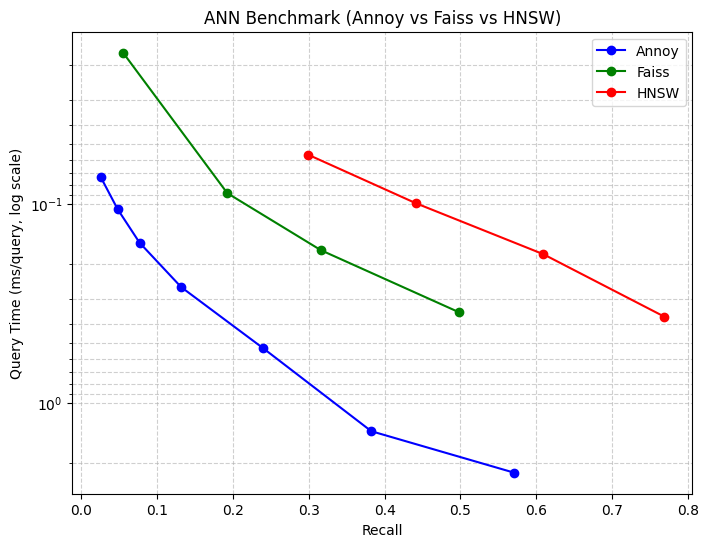

In [9]:
# -------------------------------
# Visualize the trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, the more to the right the lower
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

### Step 10 - Interpretation

Dari hasil pengukuran terlihat pola yang jelas:

* **Recall absolut rendah** (semuanya masih di bawah 0.8 pada parameter yang diuji) karena
  dataset ini adalah **uniform random 128 dimensi** tanpa struktur tetangga. Pada dimensi tinggi,
  jarak antar titik menjadi hampir seragam (*curse of dimensionality*), sehingga pemisahan
  berbasis partisi ruang menjadi sulit. Dataset nyata (gambar, teks, embedding) jauh lebih mudah
  karena vektornya mengelompok.
* **HNSW** memberi recall tertinggi pada setiap tingkat waktu query. Ini konsisten dengan sifat
  graf navigasi yang jauh lebih tahan terhadap dimensi tinggi dibanding partisi pohon.
* **FAISS IVF** berada di bawah HNSW karena dengan `nlist=100` dan `nprobe <= 20`, hanya sebagian
  kecil cluster yang diperiksa sehingga banyak tetangga sejati terlewat.
* **Annoy** paling rendah pada rentang `search_k` yang diuji. Setelah `search_k` dinaikkan ke
  20.000 (Step 8), recall-nya naik signifikan, tetapi dengan waktu query beberapa kali lipat
  lebih lambat daripada HNSW pada recall yang sebanding. Partisi berbasis *random projection
  tree* memang kurang efektif pada data uniform 128D.

Kurva ini menegaskan tidak ada satu metode yang unggul mutlak: posisi **kanan bawah** (recall
tinggi, waktu rendah) diraih HNSW di sini, tetapi dengan biaya build paling besar
(`hnsw_build`). Untuk data yang sering berubah atau dimensi rendah, Annoy/FAISS lebih ekonomis.